# BERTopic with HDBSCAN on full traces

Compare HDBSCAN with the saved 10-topic K-Means fit on the same full traces. The sentence order, cached MiniLM embeddings, 5D UMAP settings, and topic representation are shared. Prompt copies are included. HDBSCAN chooses the number of clusters and uses topic `-1` for unassigned sentences.

This exploratory fit uses `min_cluster_size=650` (about 0.5% of unique sentences) and `min_samples=15`.

In [1]:
import hashlib
import json
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from bertopic import BERTopic
from bertopic.representation import KeyBERTInspired
from hdbscan import HDBSCAN
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import adjusted_rand_score
from umap import UMAP

repo = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "analysis" / "topic_modelling.py").is_file()
)
sys.path.insert(0, str(repo / "analysis"))
from topic_modelling import _try_load_embedding_cache

results = repo / "analysis" / "topic_modelling"
baseline = results / "2026-11-28_n10"
settings = json.loads((baseline / "config_snapshot.json").read_text())
occurrences = pd.read_parquet(
    baseline / "full_trace" / "sentence_topics.parquet",
    columns=["run", "sentence", "topic_by_bert"],
).rename(columns={"topic_by_bert": "kmeans_topic"})
assert occurrences.groupby("sentence")["kmeans_topic"].nunique().max() == 1

unique = occurrences.drop_duplicates("sentence")[["sentence", "kmeans_topic"]].copy()
sentences = unique["sentence"].tolist()
key = hashlib.sha1("\n".join(sentences).encode()).hexdigest()[:12]
cache = results / "cache"
embeddings = _try_load_embedding_cache(
    sentences, cache / f"embeddings_{key}.npy", cache / f"sentences_{key}.parquet"
)
if embeddings is None or len(embeddings) != len(sentences):
    raise ValueError("The saved embeddings must match the baseline sentence order.")
print(f"{len(sentences):,} unique sentences, {len(occurrences):,} occurrences")

/Users/reginapichler/Documents/Uni/Master/Seminar/gist-reasoning-traces/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1128 16:22:26.272000 23249 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


loaded cached embeddings (130169, 384) ← /Users/reginapichler/Documents/Uni/Master/Seminar/gist-reasoning-traces/analysis/topic_modelling/cache/embeddings_6d7e0e9bc058.npy
130,169 unique sentences, 226,557 occurrences


In [2]:
clusterer = HDBSCAN(
    min_cluster_size=650, min_samples=15, metric="euclidean",
    cluster_selection_method="eom", core_dist_n_jobs=1,
)
topic_model = BERTopic(
    embedding_model=settings["EMBED_MODEL"],
    umap_model=UMAP(
        n_neighbors=settings["UMAP_N_NEIGHBORS"],
        n_components=settings["UMAP_N_COMPONENTS"],
        min_dist=settings["UMAP_MIN_DIST"],
        metric="cosine",
        random_state=settings["SEED"],
    ),
    hdbscan_model=clusterer,
    vectorizer_model=CountVectorizer(
        stop_words="english", ngram_range=(1, 2), min_df=5,
        token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z\-]+\b",
    ),
    representation_model=KeyBERTInspired(),
    calculate_probabilities=False,
)
topics, _ = topic_model.fit_transform(sentences, embeddings)
unique["hdbscan_topic"] = topics
occurrences = occurrences.merge(
    unique[["sentence", "hdbscan_topic"]], on="sentence", validate="many_to_one"
)
n_topics = unique.loc[unique["hdbscan_topic"] != -1, "hdbscan_topic"].nunique()
print(f"{n_topics} HDBSCAN topics")
print(f"Unassigned unique sentences: {unique['hdbscan_topic'].eq(-1).mean():.1%}")
print(f"Unassigned occurrences: {occurrences['hdbscan_topic'].eq(-1).mean():.1%}")

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 6293.26it/s]


38 HDBSCAN topics
Unassigned unique sentences: 17.6%
Unassigned occurrences: 16.0%


## Coverage and topics

Shares count sentence occurrences, including unassigned sentences. The stacked bars show the ten largest assigned topics overall, group smaller topics as **Other assigned**, and keep **Unassigned** visible.

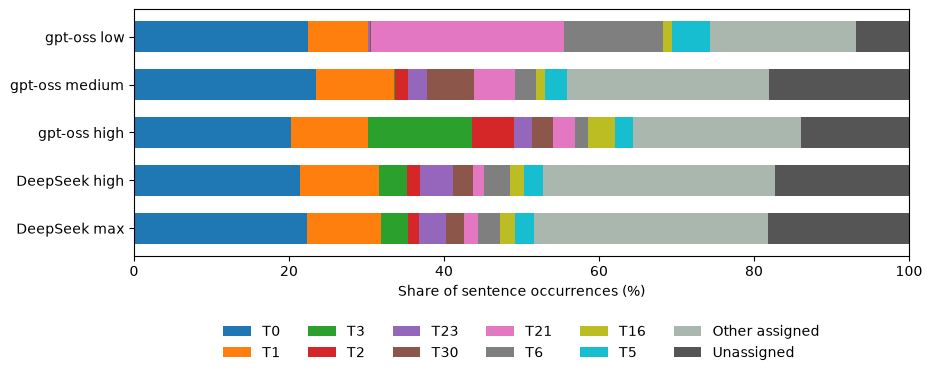

,Unassigned (%)
run,
gpt-oss low,6.8
gpt-oss medium,18.1
gpt-oss high,13.9
DeepSeek high,17.3
DeepSeek max,18.1


In [3]:
share = pd.crosstab(
    occurrences["run"], occurrences["hdbscan_topic"], normalize="index"
).reindex(settings["KEEP_RUNS"]).fillna(0)
unassigned = share.get(-1, pd.Series(0.0, index=share.index))
totals = occurrences["hdbscan_topic"].value_counts().drop(-1, errors="ignore")
top = totals.head(10).index
plot_data = share.reindex(columns=top, fill_value=0).copy()
plot_data.columns = [f"T{topic}" for topic in top]
if len(totals) > len(top):
    plot_data["Other assigned"] = share[totals.index.difference(top)].sum(axis=1)
plot_data["Unassigned"] = unassigned

palette = list(plt.get_cmap("tab10").colors[:len(top)])
if "Other assigned" in plot_data:
    palette.append("#aab7af")
palette.append("#555555")
ax = plot_data.mul(100).plot.barh(
    stacked=True, color=palette, figsize=(10, 3.2), width=.65
)
ax.set(xlim=(0, 100), xlabel="Share of sentence occurrences (%)", ylabel="")
ax.invert_yaxis()
ax.legend(loc="upper center", bbox_to_anchor=(.5, -.23), ncol=6, frameon=False)
plt.show()
display(unassigned.rename("Unassigned (%)").mul(100).round(1).to_frame())

In [4]:
info = topic_model.get_topic_info().set_index("Topic")
topic_summary = pd.DataFrame({
    "Unique sentences": unique["hdbscan_topic"].value_counts(),
    "Occurrences": occurrences["hdbscan_topic"].value_counts(),
})
topic_summary["Corpus share (%)"] = (
    100 * topic_summary["Occurrences"] / len(occurrences)
).round(2)
topic_summary["Keywords"] = info["Representation"].map(lambda terms: ", ".join(terms[:6]))
display(topic_summary.sort_values("Occurrences", ascending=False).head(16))

,Unique sentences,Occurrences,Corpus share (%),Keywords
hdbscan_topic,,,,
0,34988,48357,21.34,"scope total, total scope, scope scope, scopes,..."
-1,22944,36167,15.96,"values scope, value scope, extract values, sco..."
1,13992,22247,9.82,"values need, values, values values, value, num..."
3,4440,17149,7.57,"acquisition, value creation, industry, environ..."
2,5385,7200,3.18,"environmental data, corporate sustainability, ..."
23,1177,6777,2.99,"need output, output exactly, output, entries n..."
30,903,6309,2.78,"values, values output, need output, data outpu..."
21,1274,6194,2.73,"entries, entries need, entries final, data, to..."
6,2091,5953,2.63,"values, values excerpt, excerpt numbers, numbe..."


## Comparison with the 10 K-Means topics

The table shows the largest HDBSCAN destination for each K-Means topic among assigned unique sentences, alongside the share that HDBSCAN leaves unassigned. The overlap percentages use the original K-Means topic size as the denominator. The adjusted Rand index (ARI) uses only the sentences HDBSCAN assigned.

In [5]:
overlap = pd.crosstab(unique["kmeans_topic"], unique["hdbscan_topic"])
assigned_overlap = overlap.drop(columns=-1, errors="ignore")
sizes = overlap.sum(axis=1)
if not assigned_overlap.empty:
    best = assigned_overlap.idxmax(axis=1).where(assigned_overlap.max(axis=1).gt(0))
    comparison = pd.DataFrame({
        "Closest HDBSCAN topic": best.astype("Int64"),
        "Shared unique sentences (%)": assigned_overlap.max(axis=1).div(sizes).mul(100),
        "Unassigned (%)": overlap.get(-1, pd.Series(0, index=sizes.index)).div(sizes).mul(100),
    })
    display(comparison.round(1))
    assigned = unique[unique["hdbscan_topic"].ne(-1)]
    ari = adjusted_rand_score(assigned["kmeans_topic"], assigned["hdbscan_topic"])
    print(f"ARI on assigned unique sentences: {ari:.3f} ({len(assigned):,} sentences)")

,Closest HDBSCAN topic,Shared unique sentences (%),Unassigned (%)
kmeans_topic,,,
0,0,90.8,4.0
1,1,62.4,16.6
2,2,30.0,33.3
3,4,21.9,21.2
4,10,12.8,28.7
5,0,68.8,10.0
6,8,22.4,16.4
7,0,39.7,8.0
8,3,72.2,19.0


ARI on assigned unique sentences: 0.513 (107,225 sentences)


In [6]:
for topic in [*top[:8], -1]:
    group = unique.loc[unique["hdbscan_topic"] == topic, "sentence"]
    if group.empty:
        continue
    title = "Unassigned" if topic == -1 else f"T{topic}"
    print(f"{title} ({len(group):,} unique sentences)")
    for example in group.sample(min(4, len(group)), random_state=settings["SEED"]):
        print(" •", example[:220])
    print()

T0 (34,988 unique sentences)
 • But no CO2 emission values.
 • However, let's explore the possibility that the "CO2 emissions at manufacturing sites" chart is actually "Scope 2" and the "product transportation" chart is "Scope 3" but not total.
 • Unit: metric tons CO2.
 • The total Scope 1 & 2 excludes fugitive, so the "Scope 1 Emissions" row is the Scope 1 total for the KPI as used in their totals.

T1 (13,992 unique sentences)
 • So 1,078,781 is not part of that bullet.
 • Now we need to decide the year.
 • But "10,4" maybe 10.4?
 • "6.6.3 # 10 p.62".

T3 (4,440 unique sentences)
 • It doesn't have plain.
 • Let's use mapping from "INDUSTRY": *->I, O->E, E->N, V->D, T->U, U->S, S->T, Z->Y.
 • "VTBTIJ" maybe "MITSUB"?
 • "$POTVNFS" decode: P->O, O->N, T->S, V->U, N->M, F->E, S->R => "ONSUMER".

T2 (5,385 unique sentences)
 • Western Union’s move to reduce our footprint also includes our data centers.
 • Sustainability review continued
 • "Information disclosed in this section – GRI S

## Takeaways from this fit

- HDBSCAN finds **38 topics** and leaves **17.6% of unique sentences** and **16.0% of sentence occurrences** unassigned. The latter ranges from **6.8% for GPT-OSS low** to about **18.1% for GPT-OSS medium and DeepSeek max**.
- Scope and emissions totals, reporting years, and garbled report text recur. HDBSCAN separates JSON-only instructions (T23) and empty KPI lists (T30) into smaller groups.
- The **ARI is 0.513** among the **107,225 unique sentences** with an HDBSCAN assignment. The overlap table shows splits and merges between the two methods.
- This is one exploratory setting. The choice of a clustering method would also depend on topic interpretability and stability across parameter settings.